## EN3160 — Assignment 2
### Fitting and Alignment
**Student Name:** Deshan W. U.

**Index Number:** 230130E

In [2]:
import cv2 as cv
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

Question 1

In [4]:
# Load image
im = cv.imread('a2images/the_berry_farms_sunflower_field.jpeg', cv.IMREAD_REDUCED_COLOR_4)
assert im is not None

# Get grayscale image
gray = cv.cvtColor(im, cv.COLOR_BGR2GRAY)

In [6]:
# Select range of sigma
sigma_values = np.linspace(1, 2, 4)
# Threhsold for blob detection
threshold = 0.35

# Store responses of each scale
blob_responses = []

for sigma in sigma_values:
    print(f"Processing scale with sigma = {sigma}")

    # Apply Gaussian blur
    gaussian_blur = cv.GaussianBlur(gray, (0, 0), sigma)
    # Compute Laplacian of Gaussian (LoG)
    laplacian = cv.Laplacian(gaussian_blur, cv.CV_64F)

    # Get absolute value
    blob_response = np.abs(laplacian)

    # Threshold the response and get contours
    mask = blob_response > threshold * blob_response.max()
    contours, _ = cv.findContours(mask.astype(np.uint8), cv.RETR_EXTERNAL, cv.CHAIN_APPROX_SIMPLE)

    # Draw contours as circles
    for contour in contours:
        if len(contour) >= 5:
            # Get the center and radius of the enclosing circle from contour
            (center_x, center_y), radius = cv.minEnclosingCircle(contour)
            # Convert to integers
            center = (int(center_x), int(center_y))
            radius = int(radius)
            blob_responses.append((center, radius, sigma))

Processing scale with sigma = 1.0
Processing scale with sigma = 1.3333333333333333
Processing scale with sigma = 1.6666666666666665
Processing scale with sigma = 2.0


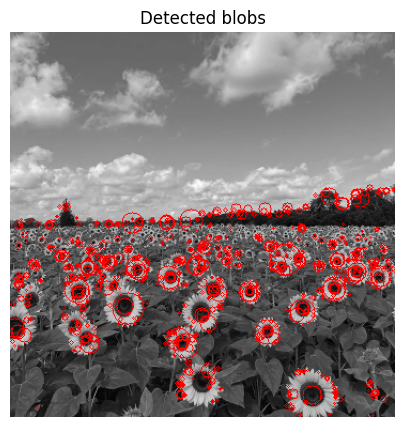

In [7]:
# Draw all detected circles with the specified line thickness
output = cv.cvtColor(gray, cv.COLOR_GRAY2BGR)
for blob in blob_responses:
    center, radius, _ = blob
    cv.circle(output, center, radius, (0, 0, 255), 1)

# Display the grayscale image with detected circles
plt.figure(figsize=(5, 5))
plt.imshow(cv.cvtColor(output, cv.COLOR_BGR2RGB), cmap='gray')
plt.axis('off')
plt.title('Detected blobs')
plt.show()

In [8]:
# Get largest circle
blobs_sorted = sorted(blob_responses, key=lambda x: x[1], reverse=True)
largest_blob = blobs_sorted[0]
center, radius, sigma = largest_blob

# Print largest circle details
print(f"Largest blob at : {center} with radius {radius} and sigma {sigma}")

Largest blob at : (110, 258) with radius 15 and sigma 2.0


The largest detected blob was located at **(110, 258)**, with a radius of **15 pixels** and a sigma value of **2.0 pixels**. The LoG-based blob detection was performed using four sigma values ranging from **1.0 to 2.0 pixels**: 1.00, 1.33, 1.67, and 2.00 pixels.


Question 2

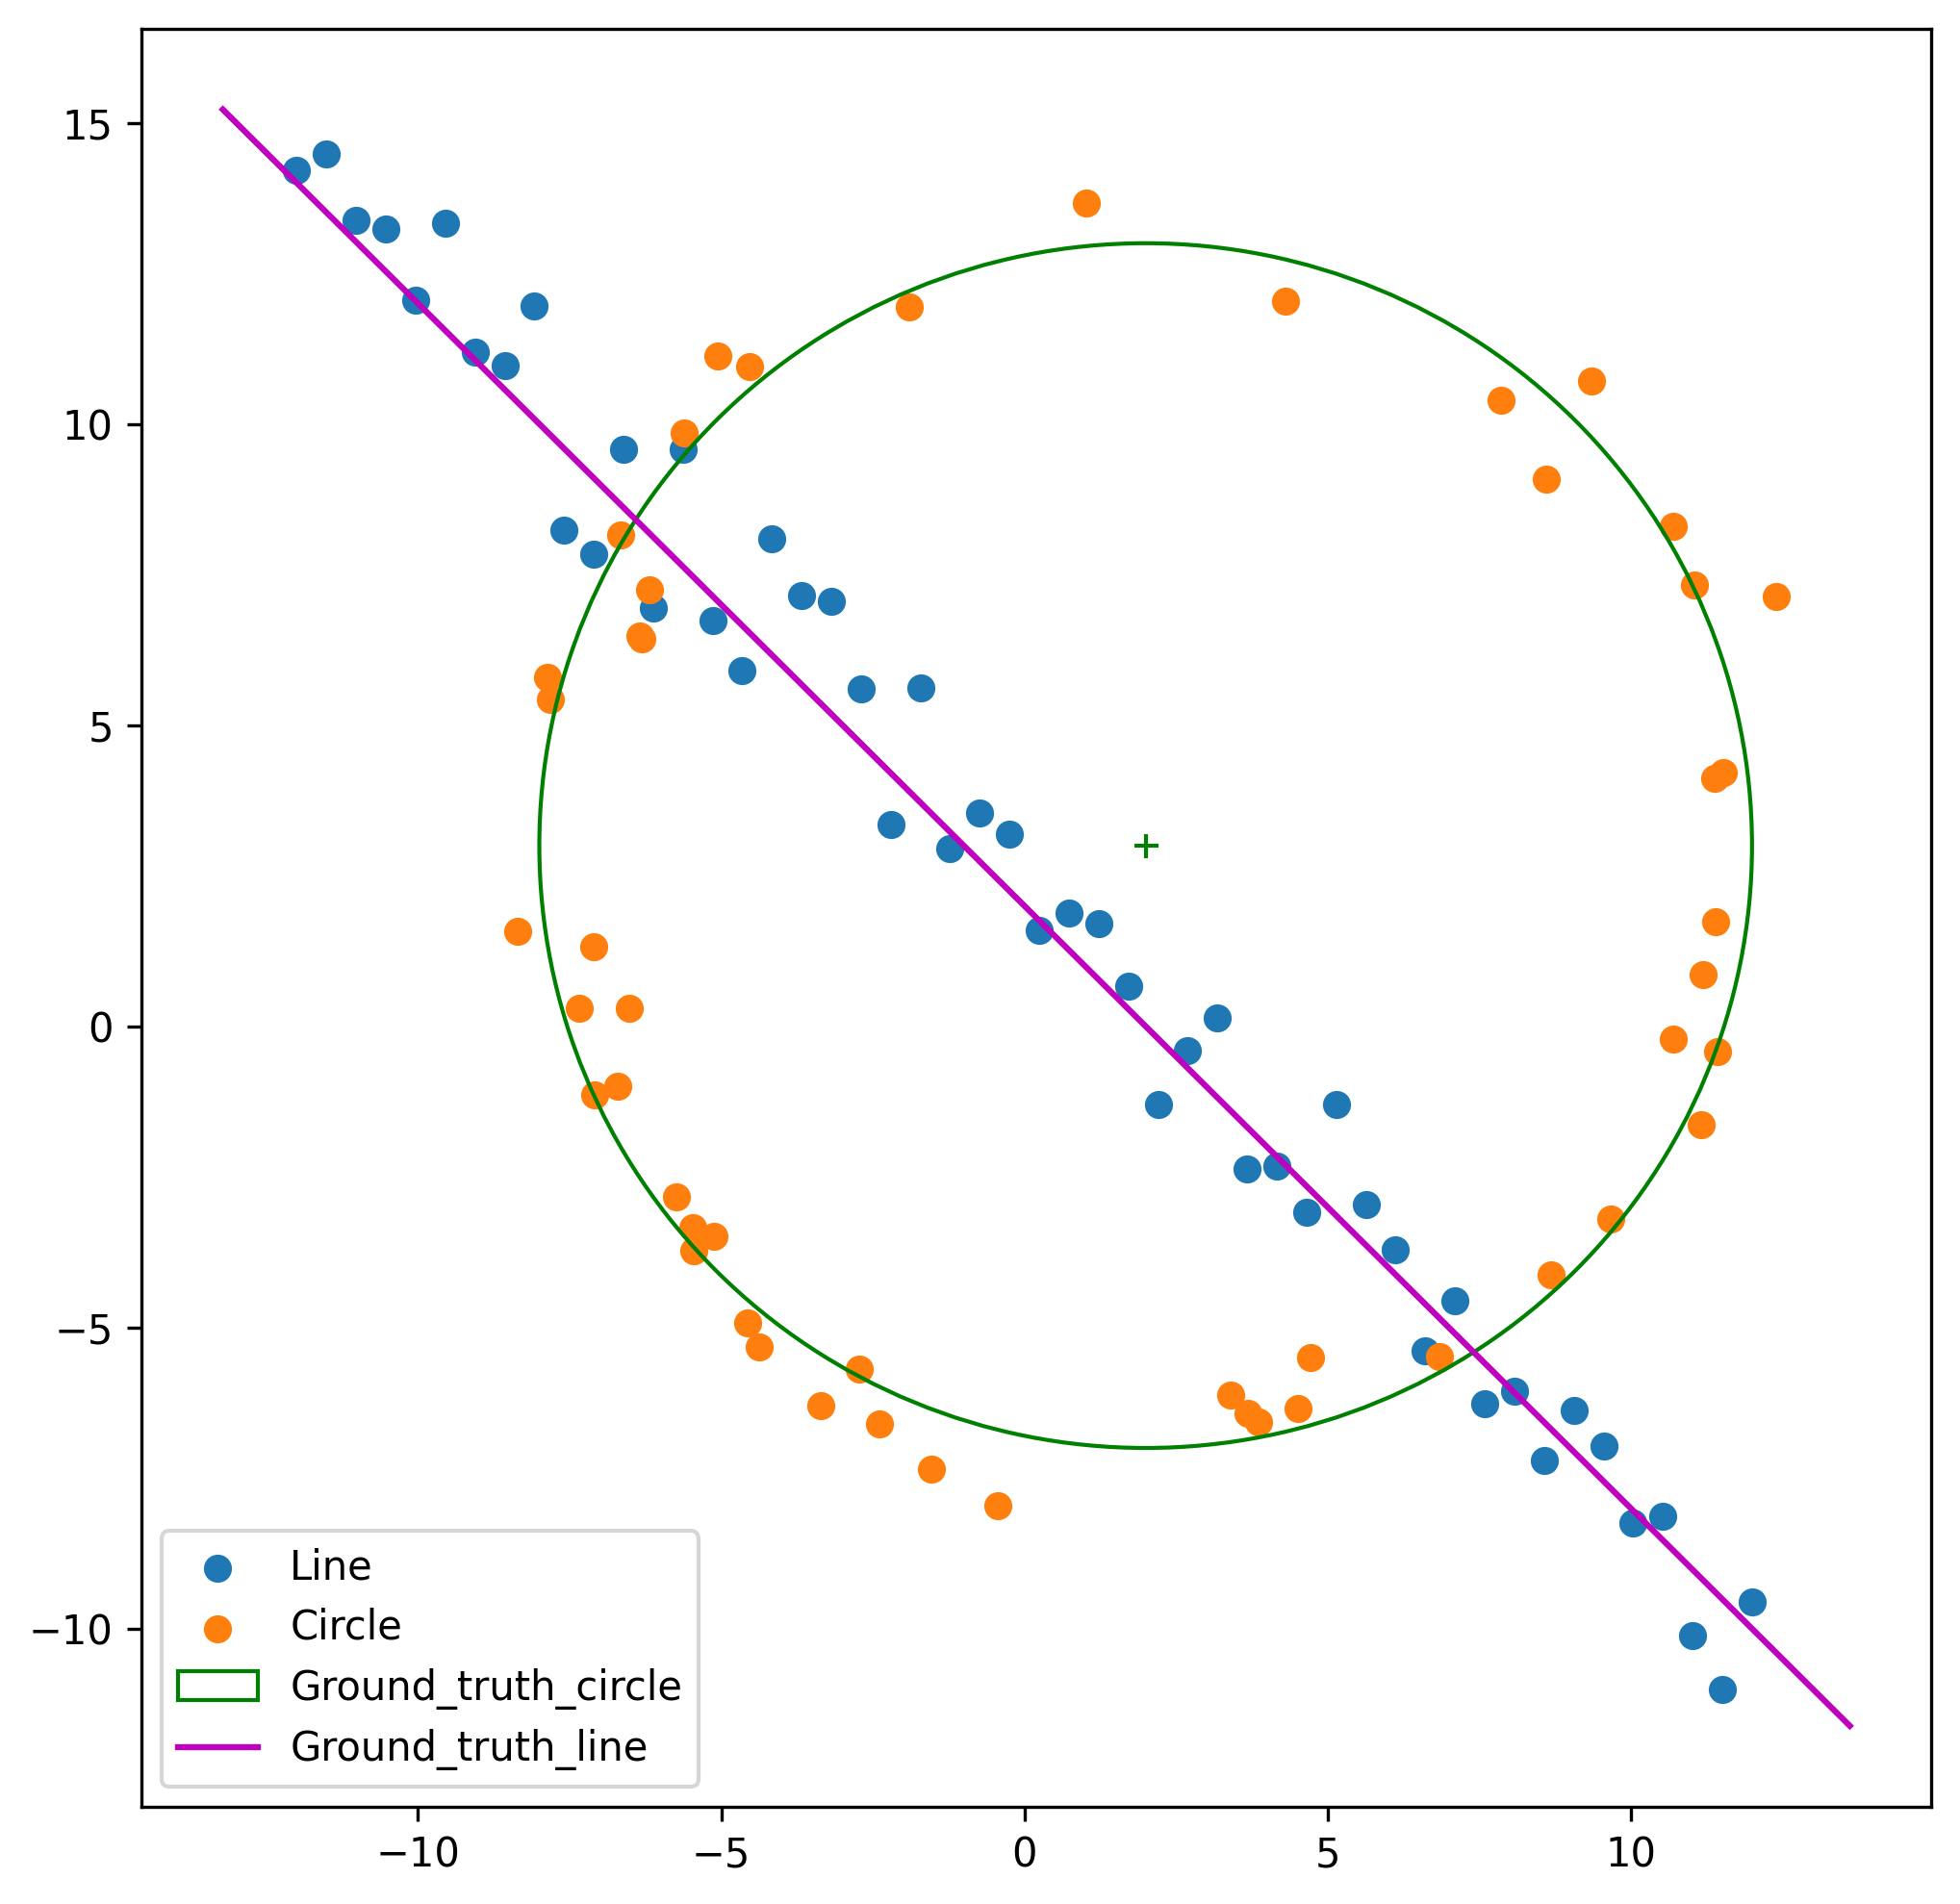

In [9]:
from scipy.optimize import minimize
from scipy import linalg
import matplotlib.pyplot as plt
import numpy as np

np.random.seed(0)
N = 100
half_n = N//2

r = 10
x0_gt, y0_gt = 2, 3  # Center
s = r/16
t = np.random.uniform(0, 2*np.pi, half_n)
n = s*np.random.randn(half_n)
x, y = x0_gt + (r + n)*np.cos(t), y0_gt + (r + n)*np.sin(t)
X_circ = np.hstack((x.reshape(half_n,1), y.reshape(half_n,1)))
s = 1.
m, b = -1, 2
x = np.linspace(-12, 12, half_n)
y = m*x + b + s*np.random.randn(half_n)
X_line = np.hstack((x.reshape(half_n,1), y.reshape(half_n,1)))
X = np.vstack((X_circ, X_line))  # All points

fig, ax = plt.subplots(1,1, figsize=(8,8), dpi=300)
ax.scatter(X_line[:,0], X_line[:,1], label='Line')
ax.scatter(X_circ[:,0], X_circ[:,1], label='Circle')
circle_gt = plt.Circle((x0_gt,y0_gt), r, color='g', fill=False, label='Ground_truth_circle')
ax.add_patch(circle_gt)
ax.plot((x0_gt), (y0_gt), '+', color='g')
x_min, x_max = ax.get_xlim()
x_ = np.array([x_min, x_max])
y_ = m*x_ + b
plt.plot(x_, y_, color='m', label='Ground_truth_line')
plt.legend()

part-a,b,c

Line   (a,b,d)  = [0.714 0.7   1.542]  inliers: 56
Circle (cx,cy,r) = [1.864 3.074 9.954]  inliers: 44


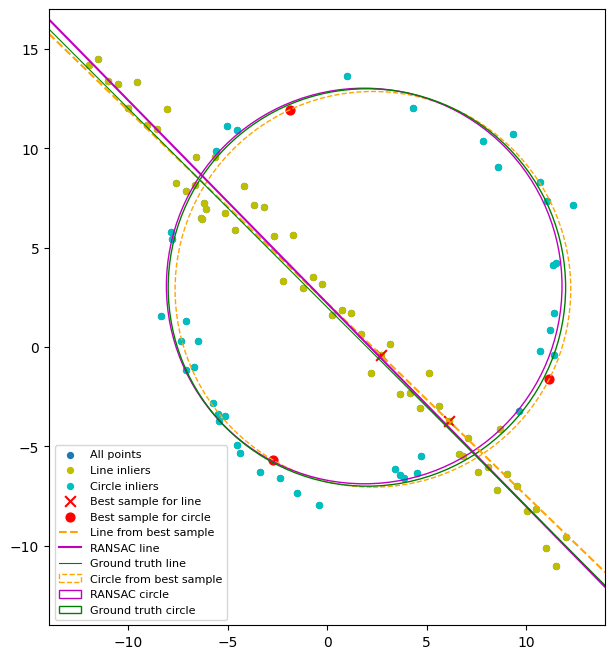

In [15]:
def line_fit(p, q):                      # (a,b,d), ||[a,b]|| = 1 by construction
    dx, dy = q - p; k = np.hypot(dx, dy)
    return np.array([dy/k, -dx/k, (dy*p[0] - dx*p[1])/k])
 
def line_err(h, P):                      # normal distance
    return np.abs(P @ h[:2] - h[2])
 
def line_refit(P, h0):                   
    return minimize(lambda h: np.sum((P @ h[:2] - h[2])**2), h0, method="SLSQP",
                    constraints={"type": "eq", "fun": lambda h: h[0]**2 + h[1]**2 - 1}).x
 
def circ_fit(p1, p2, p3):                # circle through 3 points (cx,cy,r)
    A = 2*np.array([p2 - p1, p3 - p1])
    if abs(np.linalg.det(A)) < 1e-9: return None
    c = np.linalg.solve(A, [p2@p2 - p1@p1, p3@p3 - p1@p1])
    return np.array([*c, np.linalg.norm(p1 - c)])
 
def circ_err(c, P):                      # radial error
    return np.abs(np.hypot(*(P - c[:2]).T) - c[2])
 
def circ_refit(P, c0):
    return minimize(lambda c: np.sum(circ_err(c, P)**2), c0, method="Nelder-Mead",
                    options={"xatol": 1e-8, "fatol": 1e-10, "maxiter": 5000}).x

def ransac(P, k, fit, err, thresh, min_inl, iters):
    best = None
    for _ in range(iters):
        idx = np.random.choice(len(P), k, replace=False)
        model = fit(*P[idx])
        if model is None: continue
        e = err(model, P); inl = e < thresh
        if inl.sum() >= min_inl:
            score = (inl.sum(), -e[inl].mean())
            if best is None or score > best[0]:
                best = (score, model, inl, idx)
    return best[1:]                  

l_model, l_inl, l_idx = ransac(X, 2, line_fit, line_err, 1.5, 30, 300)
rem = np.where(~l_inl)[0]
c_model, c_inl, c_idx = ransac(X[rem], 3, circ_fit, circ_err, 1.25, 30, 500)
l_best = line_refit(X[l_inl], l_model)
c_best = circ_refit(X[rem][c_inl], c_model)
print("Line   (a,b,d)  =", np.round(l_best, 3), " inliers:", l_inl.sum())
print("Circle (cx,cy,r) =", np.round(c_best, 3), " inliers:", c_inl.sum())
 

fig, ax = plt.subplots(figsize=(8, 8))
ax.scatter(*X.T, s=18, label="All points")
ax.scatter(*X[l_inl].T, c="y", s=18, label="Line inliers")
ax.scatter(*X[rem][c_inl].T, c="c", s=18, label="Circle inliers")
ax.scatter(*X[l_idx].T, c="r", marker="x", s=60, label="Best sample for line")
ax.scatter(*X[rem][c_idx].T, c="r", s=40, label="Best sample for circle")
xs = np.array([-14, 14.])
for h, kw in [(l_model, dict(c="orange", ls="--", label="Line from best sample")),
              (l_best, dict(c="m", label="RANSAC line"))]:
    ax.plot(xs, (h[2] - h[0]*xs)/h[1], **kw)
ax.plot(xs, m*xs + b, c="g", lw=0.8, label="Ground truth line")
for c, kw in [(c_model, dict(ec="orange", ls="--", label="Circle from best sample")),
              (c_best, dict(ec="m", label="RANSAC circle")),
              (np.array([x0_gt, y0_gt, r]), dict(ec="g", label="Ground truth circle"))]:
    ax.add_patch(plt.Circle(c[:2], c[2], fill=False, **kw))
ax.set_xlim(-14, 14); ax.set_ylim(-14, 17); ax.set_aspect("equal"); ax.legend(fontsize=8)
plt.show()

part-d

Fitting the circle first is less reliable. A circle model is more flexible than a line model, so a 3-point sample that falls mostly on the line can give a very large circle that explains many line points

Question 3